In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [7]:
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target
feature_names = cancer.feature_names
target_names = cancer.target_names

In [8]:
print("Original shape:", X.shape)

Original shape: (569, 30)


In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
print("\nbefore standardization:")
print(X[0:2, :5])  # Showing first 2 samples, first 5 features for readability
print("\nafter standardization:")
print(X_scaled[0:2, :5])


before standardization:
[[1.799e+01 1.038e+01 1.228e+02 1.001e+03 1.184e-01]
 [2.057e+01 1.777e+01 1.329e+02 1.326e+03 8.474e-02]]

after standardization:
[[ 1.09706398 -2.07333501  1.26993369  0.9843749   1.56846633]
 [ 1.82982061 -0.35363241  1.68595471  1.90870825 -0.82696245]]


In [11]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("\nReduced Shape:", X_pca.shape)


Reduced Shape: (569, 2)


In [12]:
variance = pca.explained_variance_ratio_
print("PC1 variance:", round(variance[0] * 100, 2), "%")
print("PC2 variance:", round(variance[1] * 100, 2), "%")
print("Total variance preserved:", round(sum(variance) * 100, 2), "%")

PC1 variance: 44.27 %
PC2 variance: 18.97 %
Total variance preserved: 63.24 %


In [13]:
df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
df["Cancer_Type"] = [target_names[i] for i in y]
print("\nFirst 5 rows of PCA DataFrame:")
print(df.head())


First 5 rows of PCA DataFrame:
        PC1        PC2 Cancer_Type
0  9.192837   1.948583   malignant
1  2.387802  -3.768172   malignant
2  5.733896  -1.075174   malignant
3  7.122953  10.275589   malignant
4  3.935302  -1.948072   malignant


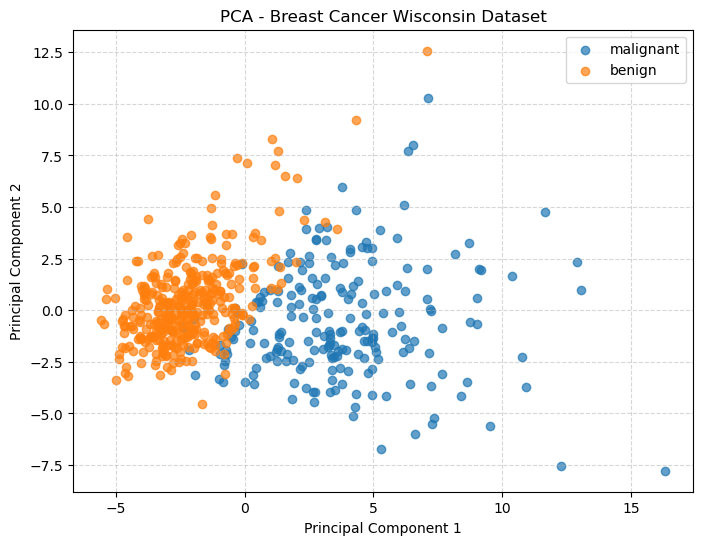

In [15]:
plt.figure(figsize=(8, 6))
for label in df["Cancer_Type"].unique():
    subset = df[df["Cancer_Type"] == label]
    plt.scatter(subset["PC1"], subset["PC2"], label=label, alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Breast Cancer Wisconsin Dataset")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()